# CKD Screening: Data Pipeline and Descriptive Statistics

Part 1 pulls the patient data from the web, calculates eGFR, and builds a DataFrame of patients with an eGFR <= 65. Part 2 analyzes that population.

## Part 1: Data pipeline

In [2]:
import csv
import json

import matplotlib.pyplot as plt
import pandas as pd
import requests

# URLs for the data files
DEMOGRAPHICS_URL = (
    "https://ruby.ils.unc.edu/~kibria/chip705_2026_fall/patient_demographics.csv"
)
CMP_URL = "https://ruby.ils.unc.edu/~kibria/chip705_2026_fall/cmp.json"

In [3]:
# defining calculation that will be used to screen patients for chronic kidney disease
def calculate_egfr(creatinine, age, sex):
    """sets values for the egfr calculation that will be conducted on male and female patients.
    They have different numerical values for the alpha, kappa, and multiplier variables so they
    must be defined separately. "If, Else" statement first checks if the patient is female, and
    will assign them their corresponding variable values. If they are not female they will be
    assigned the variable values for a male. After running through the "If/Else" statement,
    the function calculates each patient's min_term, max_term, age_term, and applies those to the egfr formula.

    Returns:
        egfr_result: uses CKD-EPI Creatinine Equation to calculate each patient's egfr
    """
    if sex.upper() == "F":
        alpha = -0.241
        multiplier = 1.012
        kappa = 0.7
    else:
        alpha = -0.302
        multiplier = 1.0
        kappa = 0.9

    min_term = min(creatinine / kappa, 1) ** alpha
    max_term = max(creatinine / kappa, 1) ** -1.200
    age_term = 0.9938**age
    egfr_result = 142 * min_term * max_term * age_term * multiplier
    return egfr_result

In [4]:
# requests the patient_demographics.csv file from the web,
# creates an individual row for each patient and their data in the file using DictReader,
# strip() removes white space at the beginning and end of the string to help create each row
demographic_dictionary = {}
demographics_response = requests.get(DEMOGRAPHICS_URL)
demographics_response.raise_for_status()
demographics_reader = csv.DictReader(demographics_response.text.splitlines())
for row in demographics_reader:
    demographic_dictionary[row["patient_id"].strip()] = row

# requests the json file from the web, reads it, and converts it into a dictionary
cmp_response = requests.get(CMP_URL)
cmp_response.raise_for_status()
cmp_data = json.loads(cmp_response.text)

In [ ]:
joined_data = []

# reads through cmp_data and cleans the patient_id's.
# Matches records between the json and csv files using patient ID.
# Converts numerical values into decimal points, and assigns them to their respective variable names that will be used to calculate egfr.
# calculates egfr and assigns it to egfr_calculated.
# filters patients to include them in the joined_data list if they have an egfr <= 65.
# height (inches) and weight (pounds) come from the demographics file, and BMI is calculated from them.
for patient_id, test_records in cmp_data.items():
    clean_id = patient_id.strip()

    if clean_id in demographic_dictionary:
        patient_demographics = demographic_dictionary[clean_id]

        for lab_test in test_records:
            if lab_test["measure"] == "Creatinine":
                cre = float(lab_test["patient_measure"])
                age = float(patient_demographics["age"])
                sex = patient_demographics["sex"].strip()
                egfr_calculated = calculate_egfr(cre, age, sex)

                if egfr_calculated <= 65.0:
                    height = float(patient_demographics["height_inches"])
                    weight = float(patient_demographics["weight_lbs"])
                    bmi = 703 * weight / height**2

                    joined_data.append(
                        {
                            "age": age,
                            "height": height,
                            "weight": weight,
                            "bmi": bmi,
                            "sex": sex,
                            "egfr_calculated": egfr_calculated,
                        }
                    )

In [6]:
# converts the joined_data list into a Pandas DataFrame with one row per patient
results_df = pd.DataFrame(
    joined_data, columns=["age", "height", "weight", "bmi", "sex", "egfr_calculated"]
)
print(f"Patients with eGFR <= 65: {len(results_df)}")
results_df.head()

Patients with eGFR <= 65: 41


,age,height,weight,bmi,sex,egfr_calculated
0,26.0,84.0,199.0,19.826672,M,58.487410
1,57.0,76.0,235.0,28.601974,M,39.445537
2,25.0,74.0,298.0,38.256757,F,45.387805
3,41.0,78.0,250.0,28.887245,M,60.135801
4,18.0,69.0,207.0,30.565217,M,58.604723


## Part 2: Analysis of patients with eGFR <= 65

### 1. Descriptive statistics for age, height, and weight

In [7]:
# age in years, height in inches, weight in pounds
stats = results_df[["age", "height", "weight"]].describe().round(2)
stats

,age,height,weight
count,41.00,41.00,41.00
mean,41.44,72.63,221.90
std,14.62,7.42,38.82
min,18.00,61.00,144.00
25%,29.00,65.00,194.00
50%,40.00,73.00,224.00
75%,56.00,79.00,247.00
max,64.00,84.00,298.00


### 2. Average eGFR by BMI category

BMI categories: Underweight (< 18.5), Normal (18.5 to 24.9), Overweight (25.0 to 29.9), Obese (>= 30.0).

bmi_category
Underweight    63.77
Normal         51.98
Overweight     53.23
Obese          50.95
Name: egfr_calculated, dtype: float64


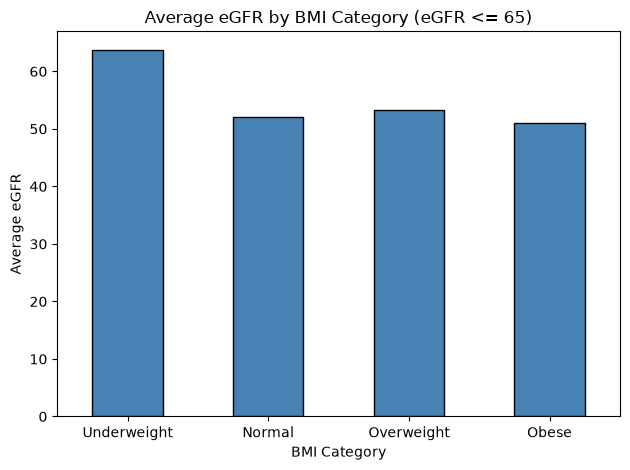

In [ ]:
df = results_df.copy()
bmi_bins = [0, 18.5, 25, 30, float("inf")]
bmi_labels = ["Underweight", "Normal", "Overweight", "Obese"]
df["bmi_category"] = pd.cut(df["bmi"], bins=bmi_bins, labels=bmi_labels, right=False)

avg_egfr_by_bmi = df.groupby("bmi_category", observed=False)["egfr_calculated"].mean().round(2)
print(avg_egfr_by_bmi)

ax = avg_egfr_by_bmi.plot(kind="bar", color="steelblue", edgecolor="black", rot=0)
ax.set_title("Average eGFR by BMI Category")
ax.set_xlabel("BMI Category")
ax.set_ylabel("Average eGFR")
plt.tight_layout()
plt.show()

### 3. Age vs. eGFR

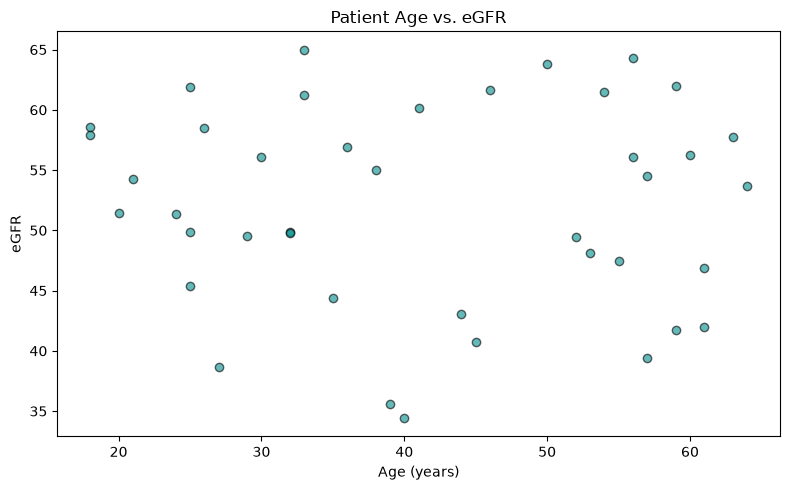

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df["age"], df["egfr_calculated"], alpha=0.6, color="darkcyan", edgecolor="black")
plt.title("Patient Age vs. eGFR")
plt.xlabel("Age (years)")
plt.ylabel("eGFR")
plt.tight_layout()
plt.show()

### 4. Patient sex

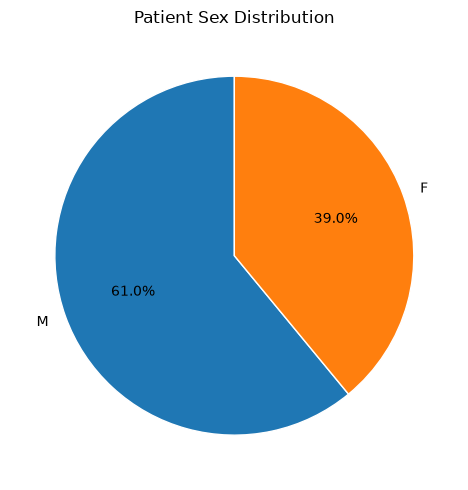

In [15]:
sex_counts = df["sex"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(sex_counts, labels=sex_counts.index, autopct="%1.1f%%", startangle=90,
        wedgeprops={"edgecolor": "white"})
plt.title("Patient Sex Distribution")
plt.tight_layout()
plt.show()